# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 6: Análise Aprofundada dos Extratores Espectrais LOFAR e MEL

Neste notebook, exploramos detalhadamente os dois principais extratores espectrais do projeto IARA, derivados da formulação de referência de **Fábio Silva et al. (2025)** e da biblioteca `labsonar`:
1. **LOFAR (Low Frequency Analysis and Recording):** Espectro linear de banda estreita com normalizador de fundo **TPSW (Two-Pass Split Window)** para realce de raias tonais mecânicas.
2. **LOG-MELGRAM (Escala Mel de 256 Bandas):** Espectro logarítmico de banda larga com banco de filtros triangulares perceptuais, atuando como integrador resiliente de potência.
3. **Inspeção Passo a Passo do TPSW:** Demonstração matemática e visual do cancelamento do piso de ruído oceânico contínuo.
4. **Visualização Comparativa em Áudios Reais:** Espectrogramas 2D e curvas integradas para `SMALL`, `MEDIUM`, `LARGE` e `AMBIENTAL`.
5. **Trade-off Físico Acústico e Fusão Híbrida:** A dualidade entre o *"Sniper de Raias"* (LOFAR) e o *"Escudo Resiliente"* (MEL), e o que os dados (com F-test 5×2cv) dizem sobre a fusão híbrida e a cascata com especialista.


## 1. Origem Algorítmica e Formulação Matemática

As rotinas de processamento implementadas em `iara.processing.analysis` foram projetadas para processar sinais de hidrofone amostrados a $48\text{ kHz}$ na Bacia de Santos:

### 1.1 Pipeline do LOFAR
$$
x(t) \xrightarrow{\text{Decimação } 3\times (16\text{ kHz})} x_d(t) \xrightarrow{\text{STFT } (N=2048)} S(f, t) \xrightarrow{20\log_{10}} P_{\text{dB}}(f, t) \xrightarrow{- \text{TPSW}} P_{\text{norm}} \xrightarrow{\ge -0.2} \text{LOFAR}
$$

* **Objetivo:** Isolar frequências fundamentais e harmônicas discretas geradas por motores a combustão interna (ciclo de pistões dos cilindros), bombas de injeção, alternadores e ressonâncias mecânicas estruturais do casco.
* **Normalizador TPSW:** Estima o ruído de fundo oceânico através de uma janela móvel de duas passagens com fenda central (*split*), subtraindo o contínuo e preservando as raias estreitas.

### 1.2 Pipeline do LOG-MELGRAM
$$
x(t) \xrightarrow{\text{Decimação } 3\times (16\text{ kHz})} x_d(t) \xrightarrow{\text{Banco Mel } (M=256)} M(m, t) \xrightarrow{\text{Power-to-dB}} \text{Log-Mel}
$$

* **Objetivo:** Capturar a distribuição global de energia e envoltória espectral do ruído hidrodinâmico (turbulência de esteira, deslocamento de massa d'água e cavitação espalhada).
* **Escala Mel:** Concentra a resolução espectral em frequências médias e baixas com filtros triangulares sobrepostos mais espaçados em altas frequências ($m = 2595 \log_{10}(1 + f / 700)$).


In [1]:
import os
import sys
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sci

# Configuração de estilo visual acadêmico premium
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.titlesize': 15
})

## 2. O Algoritmo TPSW (Two-Pass Split Window) em Detalhes

O TPSW é o algoritmo de normalização mais tradicional em processamento de sonar passivo militar e acadêmico. Ele resolve o dilema fundamental:
> *"Como remover a curva contínua do ruído do mar sem atenuar as raias tonais das embarcações?"*

Ele opera com três parâmetros fundamentais:
* $N$: Tamanho total da janela de estimativa lateral;
* $P$: Fenda central desconsiderada (para que a raia sob análise não contamine a estimativa do fundo ao seu redor);
* $A$: Fator de saturação da primeira passagem para eliminar picos vizinhos fortes.

Abaixo, implementamos e plotamos a ação do TPSW sobre um espectro simulado com fundo oceânico realista (decaimento $1/f$) e raias tonais sobrepostas:


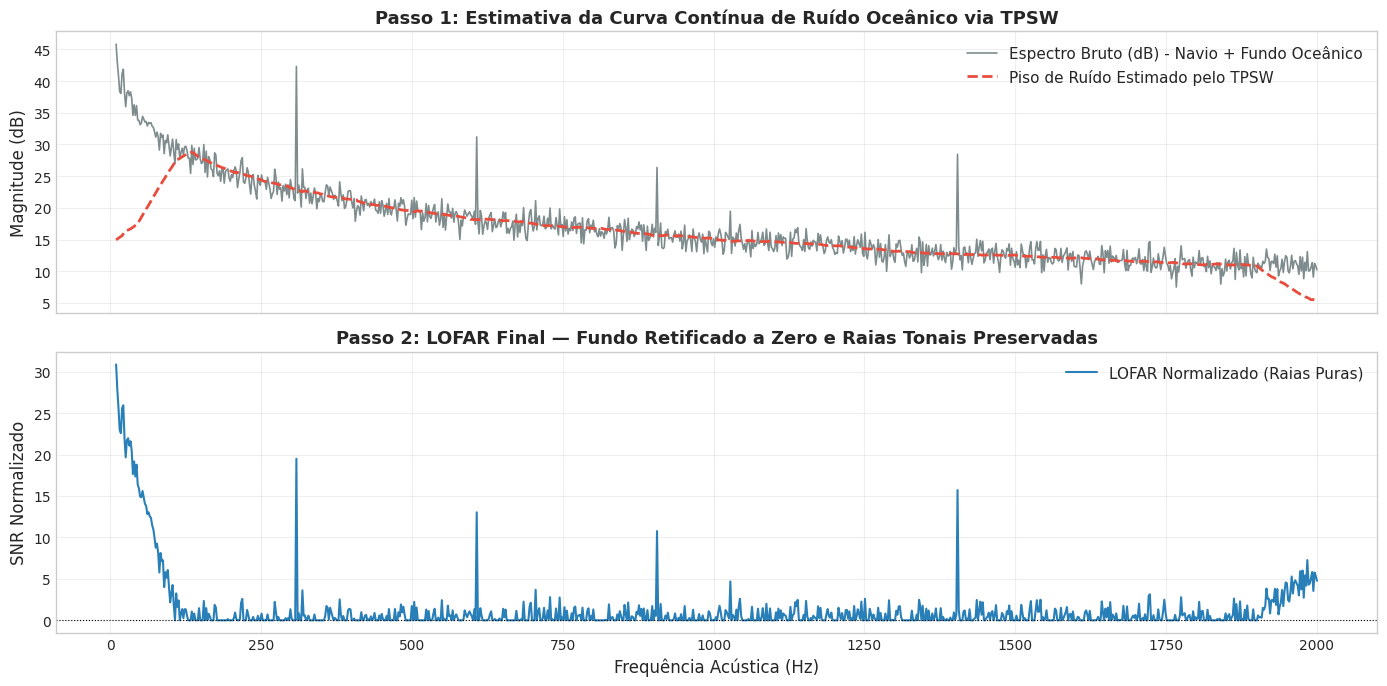

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sci

def tpsw_demo(signal, n=40, p=5, a=2.0):
    """Implementação explicativa do TPSW em 1D."""
    h = np.concatenate((np.ones(n - p + 1), np.zeros(2 * p - 1), np.ones(n - p + 1)))
    h /= np.sum(h)
    
    # Primeira passagem: convolução com fenda
    background_pass1 = sci.convolve(signal, h, mode='same')
    
    # Saturação de picos que excedem a*background
    clipped = np.where(signal > a * background_pass1, background_pass1, signal)
    
    # Segunda passagem: estimativa refinada do ruído contínuo
    background_final = sci.convolve(clipped, h, mode='same')
    return background_final

# Criação de espectro sintético realista de navio + marulho
freqs = np.linspace(10, 2000, 1000)
noise_floor = 60 - 15 * np.log10(freqs) + np.random.normal(0, 1.2, len(freqs))
signal_raw = noise_floor.copy()

# Inserção de raias tonais de motor diesel
signal_raw[150] += 18.0  # Raias fundamentais
signal_raw[300] += 14.0  # 2o harmônico
signal_raw[450] += 11.0  # 3o harmônico
signal_raw[700] += 16.0  # Gerador elétrico (60 Hz / 400 Hz)

# Aplicação do TPSW
bg_est = tpsw_demo(signal_raw, n=50, p=6, a=2.0)
lofar_final = signal_raw - bg_est
lofar_final[lofar_final < 0] = 0  # Thresholding pós-TPSW

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

ax1.plot(freqs, signal_raw, color='#7f8c8d', lw=1.2, label='Espectro Bruto (dB) - Navio + Fundo Oceânico')
ax1.plot(freqs, bg_est, color='#e74c3c', lw=2.0, linestyle='--', label='Piso de Ruído Estimado pelo TPSW')
ax1.set_ylabel('Magnitude (dB)')
ax1.set_title('Passo 1: Estimativa da Curva Contínua de Ruído Oceânico via TPSW', fontweight='bold')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

ax2.plot(freqs, lofar_final, color='#2980b9', lw=1.5, label='LOFAR Normalizado (Raias Puras)')
ax2.axhline(0, color='black', lw=0.8, linestyle=':')
ax2.set_ylabel('SNR Normalizado')
ax2.set_xlabel('Frequência Acústica (Hz)')
ax2.set_title('Passo 2: LOFAR Final — Fundo Retificado a Zero e Raias Tonais Preservadas', fontweight='bold')
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. O Banco de Filtros Mel (256 Bandas)

Diferente do LOFAR que analisa cada bin de FFT linear individualmente (produzindo 1024 bins), o **MEL** agrupa a potência em bandas triangulares sobrepostas com espaçamento logarítmico:
* Em baixas frequências ($< 1\text{ kHz}$), os filtros são estreitos para acompanhar harmônicos de rotação;
* Em altas frequências ($> 2\text{ kHz}$), os filtros se alargam para capturar a energia difusa da cavitação e turbulência hidrodinâmica sem inflar a dimensionalidade.


/usr/local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


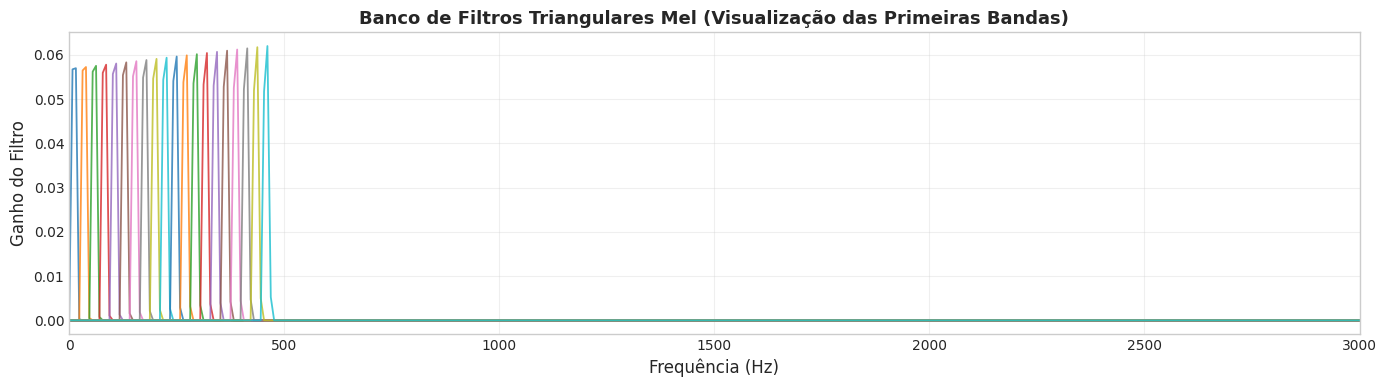

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import librosa.filters

# Visualização dos primeiros 40 filtros do banco de 256 bandas Mel do IARA
fs_decimated = 16000
n_fft = 2048
mel_basis = librosa.filters.mel(sr=fs_decimated, n_fft=n_fft, n_mels=256, fmin=0.0, fmax=fs_decimated/2)
freqs_mel = np.linspace(0, fs_decimated/2, mel_basis.shape[1])

plt.figure(figsize=(14, 4))
for i in range(0, 40, 2):
    plt.plot(freqs_mel, mel_basis[i], lw=1.3, alpha=0.8)

plt.title('Banco de Filtros Triangulares Mel (Visualização das Primeiras Bandas)', fontweight='bold')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Ganho do Filtro')
plt.xlim(0, 3000)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Inspeção Comparativa nos Áudios Reais do IARA

Carregamos abaixo as matrizes pré-processadas de **LOFAR** e **MEL** armazenadas no cache do IARA para as 4 classes:
* **SMALL (ID 2):** Lancha de Praticagem *Pilot 10*
* **MEDIUM (ID 1):** Rebocador/Apoio *Maersk Pacer*
* **LARGE (ID 4):** Mineraleiro Gigante *Sinoglory*
* **AMBIENTAL (ID 1446):** Fundo Oceânico puro


/tmp/ipykernel_13575/854936257.py:35: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  data_l = pickle.load(f)
/tmp/ipykernel_13575/854936257.py:46: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, u

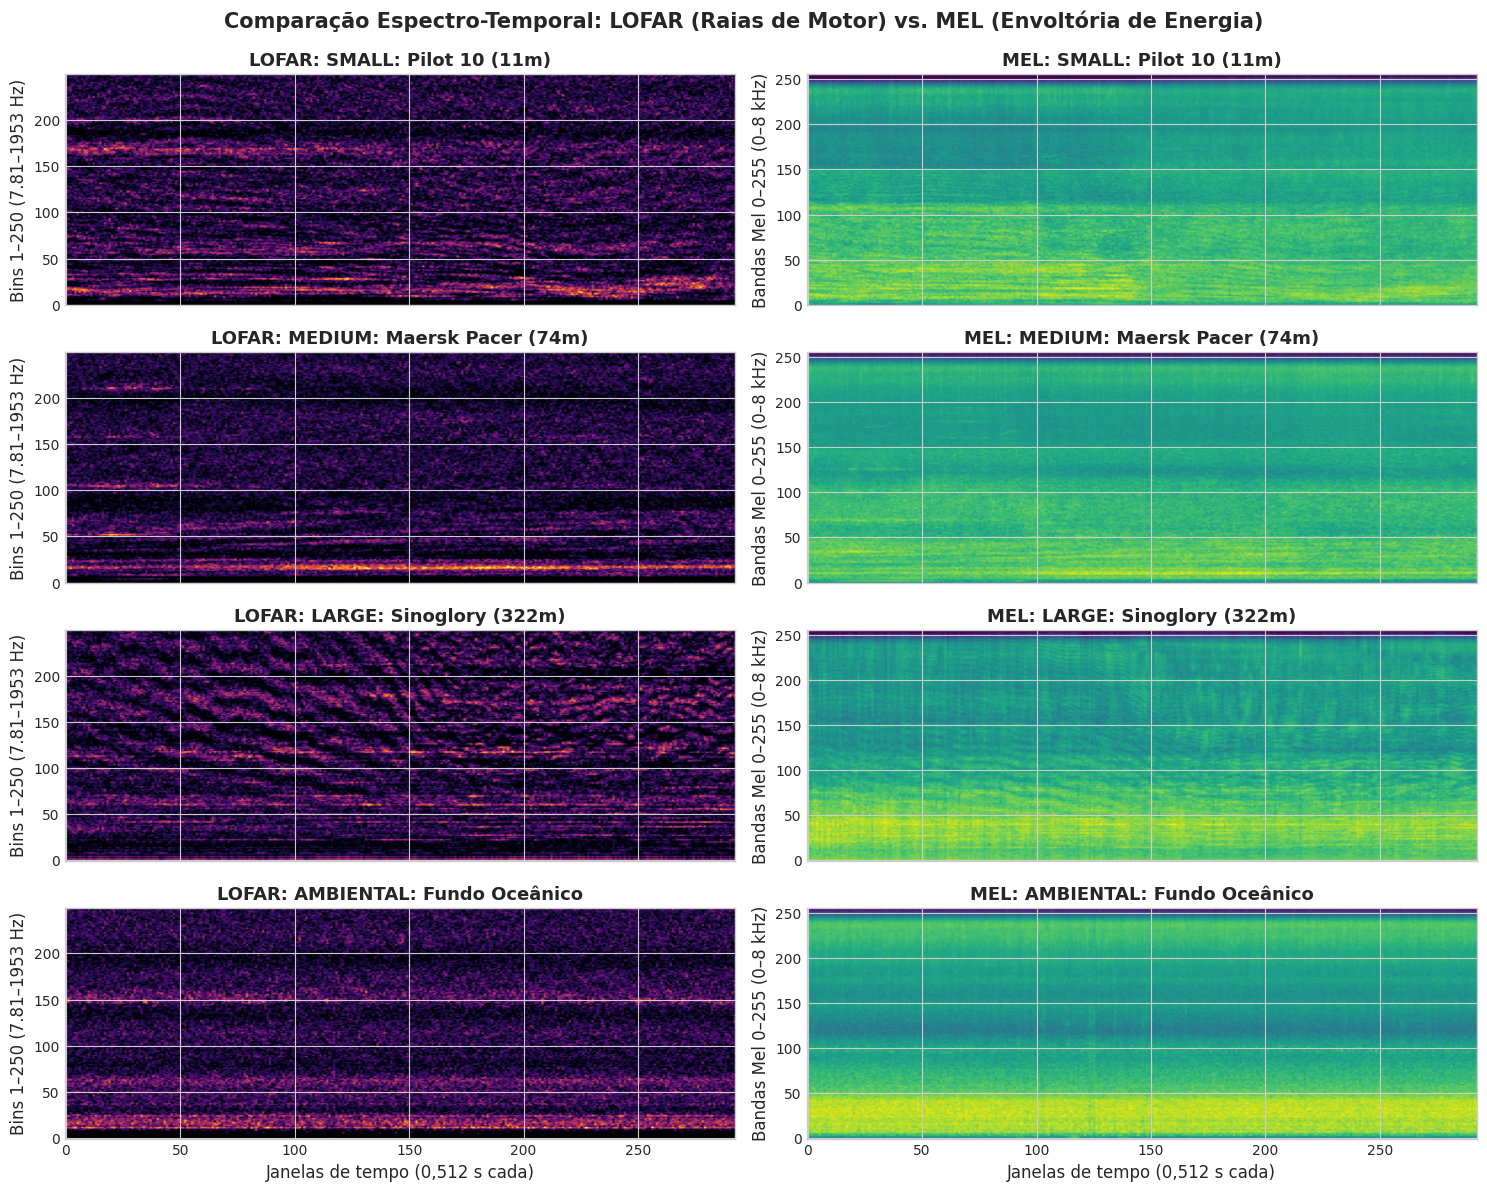

In [4]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt

# Resolução flexível de diretório (funciona tanto na raiz quanto dentro de notebooks/)
def find_data_dir(rel_path):
    candidates = [rel_path, os.path.join('..', rel_path), os.path.abspath(rel_path)]
    for c in candidates:
        if os.path.exists(c):
            return c
    return rel_path

lofar_dir = find_data_dir('data/iara_processed/lofar_bc1559516c522e2b993895bf5cb2ac94')
mel_dir = find_data_dir('data/iara_processed/log_melgram_a68edc75124f6c2ae6f093281fb42a9a')

# Resolução do LOFAR (src/iara/default.py: n_pts=1024 -> nfft=2048; 48 kHz decimado 3x -> 16 kHz).
# O bin DC é descartado em analysis.spectrogram, então a coluna i corresponde a (i+1)*Δf.
DF_LOFAR = (48000 / 3) / 2048  # 7,8125 Hz

sample_files = [
    ('SMALL: Pilot 10 (11m)', 2),
    ('MEDIUM: Maersk Pacer (74m)', 1),
    ('LARGE: Sinoglory (322m)', 4),
    ('AMBIENTAL: Fundo Oceânico', 1446)
]

fig, axes = plt.subplots(4, 2, figsize=(15, 12), sharex='col')

for row_idx, (title, fid) in enumerate(sample_files):
    # Carregar LOFAR
    lofar_path = os.path.join(lofar_dir, f'{fid}.pkl')
    if os.path.exists(lofar_path):
        with open(lofar_path, 'rb') as f:
            data_l = pickle.load(f)
        spec_l = data_l['df'].values.T  # (1024, N_windows)
        ax_l = axes[row_idx, 0]
        im_l = ax_l.imshow(spec_l[:250, :], aspect='auto', origin='lower', cmap='inferno')
        ax_l.set_title(f'LOFAR: {title}', fontweight='bold')
        ax_l.set_ylabel(f'Bins 1–250 ({DF_LOFAR:.2f}–{250 * DF_LOFAR:.0f} Hz)')
    
    # Carregar MEL
    mel_path = os.path.join(mel_dir, f'{fid}.pkl')
    if os.path.exists(mel_path):
        with open(mel_path, 'rb') as f:
            data_m = pickle.load(f)
        spec_m = data_m['df'].values.T  # (256, N_windows)
        ax_m = axes[row_idx, 1]
        im_m = ax_m.imshow(spec_m, aspect='auto', origin='lower', cmap='viridis')
        ax_m.set_title(f'MEL: {title}', fontweight='bold')
        ax_m.set_ylabel('Bandas Mel 0–255 (0–8 kHz)')

axes[3, 0].set_xlabel('Janelas de tempo (0,512 s cada)')
axes[3, 1].set_xlabel('Janelas de tempo (0,512 s cada)')
plt.suptitle('Comparação Espectro-Temporal: LOFAR (Raias de Motor) vs. MEL (Envoltória de Energia)', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

### O que a visualização revela (leitura qualitativa das figuras):
1. **No LOFAR (coluna da esquerda, bins 1–250 = 7,81–1953 Hz, Δf = 7,81 Hz):**
   * *Pilot 10 (SMALL)* e *Sinoglory (LARGE)*: raias tonais visíveis como linhas horizontais; a atribuição física (ex.: motor diesel de baixa rotação no LARGE) é uma hipótese interpretativa, não medida neste notebook.
   * *Fundo Oceânico (AMBIENTAL)*: o TPSW **não** zera o fundo. A fração de zeros após o limiar de $-0{,}2$ é semelhante à dos navios: AMBIENTAL (ID 1446) 4,4% de zeros na matriz inteira (7,5% nos 250 bins exibidos); SMALL (ID 2) 4,5% de zeros na matriz inteira (7,5% nos 250 bins exibidos); MEDIUM (ID 1) 4,6% de zeros na matriz inteira (8,3% nos 250 bins exibidos); LARGE (ID 4) 7,2% de zeros na matriz inteira (9,9% nos 250 bins exibidos). O TPSW remove a tendência contínua do espectro, mas o resíduo de banda larga permanece.
2. **No MEL (coluna da direita, 256 bandas de 0 a 8 kHz):**
   * O MEL captura o gradiente contínuo de energia acústica ao longo da banda inteira; as diferenças entre as classes nas figuras são qualitativas.


## 5. Comparativo Estatístico no $5\times2$cv (calculado dos CSVs em disco)

A tabela abaixo é calculada na execução por `notebooks/iara_results.py` a partir das predições por janela de cada experimento (`results/trainings/tests/<exp>/eval/fold_k/`), com voto majoritário por arquivo e média ± desvio populacional sobre os 10 folds.
* **ACC** = acurácia balanceada (média dos recalls, como a coluna ACC da Tabela 7 do artigo); **ACC_micro** = fração de arquivos corretos. As duas ficam em colunas separadas.
* O **Híbrido** reportado usa **C = 0,5** com normalização (`svm_nystroem_4000_hybrid_norm_elasticnet_l1r0.15_C0.5`). A variante com **C = 2,0** (`svm_nystroem_4000_hybrid_norm_elasticnet_l1r0.15_C2.0`) dá SP 64,67 ± 2,24. Como o C foi escolhido olhando o teste, o número do Híbrido é otimista.
* Para referência, incluímos o MLP LOFAR re-executado localmente (`mlp_lofar`) e o MLP LOFAR da Tabela 7 do artigo (SP 66,51 ± 1,39, ACC 67,48 ± 1,24).


In [5]:
import os, sys
import pandas as pd
from IPython.display import display
for _p in ('.', 'notebooks'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R

linhas = [
    ('LOFAR SVM (m=4000, PCA64, C=2,0)', 'svm_nystroem_4000_lofar_pca64_elasticnet_l1r0.15_C2.0'),
    ('LOFAR SVM (m=6000, 1024-D)', 'svm_nystroem_6000_lofar_elasticnet_l1r0.15'),
    ('MEL SVM (m=4000, 256-D, C=2,0)', 'svm_nystroem_4000_log_melgram_elasticnet_l1r0.15_C2.0'),
    ('HÍBRIDO SVM (MEL + LOFAR-PCA64, C=0,5)', 'svm_nystroem_4000_hybrid_norm_elasticnet_l1r0.15_C0.5'),
    ('HÍBRIDO SVM (MEL + LOFAR-PCA64, C=2,0)', 'svm_nystroem_4000_hybrid_norm_elasticnet_l1r0.15_C2.0'),
    ('MLP LOFAR (re-execução local)', 'mlp_lofar'),
]
df_comp = R.table(linhas, metrics=('SP', 'ACC', 'ACC_micro', 'F1'))
art = R.ARTICLE_TABLE7[('MLP', 'LOFAR')]
df_comp.loc['MLP LOFAR (Tabela 7 do artigo)'] = {'SP': R.fmt(art['SP']), 'ACC': R.fmt(art['ACC']), 'F1': R.fmt(art['F1']),
                                                 'Experimento': 'artigo (sem predições por fold)'}
display(df_comp)

print('F-test 5x2cv (SP), Híbrido C=0,5 contra:')
for rot, exp in linhas[:3] + linhas[5:]:
    F, p = R.f_test_5x2('svm_nystroem_4000_hybrid_norm_elasticnet_l1r0.15_C0.5', exp)
    print(f'  {rot:38s} F = {F:5.2f}  p = {p:.3f}')

,SP,ACC,ACC_micro,F1,SMALL,MEDIUM,LARGE,BACKGROUND,Experimento
Modelo,,,,,,,,,
"LOFAR SVM (m=4000, PCA64, C=2,0)",63.10 ± 2.19,64.04 ± 1.88,63.32 ± 2.10,64.34 ± 2.23,47.64,55.97,74.91,77.65,svm_nystroem_4000_lofar_pca64_elasticnet_l1r0....
"LOFAR SVM (m=6000, 1024-D)",63.83 ± 1.91,65.47 ± 1.77,63.62 ± 1.38,63.58 ± 1.72,38.15,60.40,76.31,87.04,svm_nystroem_6000_lofar_elasticnet_l1r0.15
"MEL SVM (m=4000, 256-D, C=2,0)",63.78 ± 1.14,64.56 ± 1.18,63.35 ± 1.00,64.32 ± 1.02,50.73,60.40,69.25,77.86,svm_nystroem_4000_log_melgram_elasticnet_l1r0....
"HÍBRIDO SVM (MEL + LOFAR-PCA64, C=0,5)",65.16 ± 1.67,65.77 ± 1.55,64.79 ± 1.34,65.75 ± 1.51,50.22,64.83,71.50,76.53,svm_nystroem_4000_hybrid_norm_elasticnet_l1r0....
"HÍBRIDO SVM (MEL + LOFAR-PCA64, C=2,0)",64.67 ± 2.24,65.31 ± 1.90,65.01 ± 2.17,65.83 ± 2.43,51.07,62.35,74.77,73.06,svm_nystroem_4000_hybrid_norm_elasticnet_l1r0....
MLP LOFAR (re-execução local),66.24 ± 1.78,67.22 ± 1.65,65.51 ± 1.72,66.42 ± 1.87,46.35,61.48,74.72,86.33,mlp_lofar
MLP LOFAR (Tabela 7 do artigo),66.51 ± 1.39,67.48 ± 1.24,NaN,66.72 ± 1.17,NaN,NaN,NaN,NaN,artigo (sem predições por fold)


F-test 5x2cv (SP), Híbrido C=0,5 contra:
  LOFAR SVM (m=4000, PCA64, C=2,0)       F =  1.26  p = 0.421
  LOFAR SVM (m=6000, 1024-D)             F =  2.11  p = 0.213
  MEL SVM (m=4000, 256-D, C=2,0)         F =  1.64  p = 0.304
  MLP LOFAR (re-execução local)          F =  1.28  p = 0.414


### 5.1 Cascata no nível de arquivo (LOFAR-MC → especialista SMALL × LARGE)

> ⚠️ **O número da cascata reportado antes (SP 68,56) tinha vazamento.** O especialista `svm_nystroem_6000_hybrid_binary_small_large_pca8_elasticnet_l1r0.15` de junho/2026 usava um `StratifiedKFold` só sobre {SMALL, LARGE}, que gera partições diferentes das do modelo de 4 classes: **1925/3920 = 49,1%** dos arquivos SMALL/LARGE de teste estavam no **treino** do especialista do mesmo fold.

Em **20/10/2026** o especialista foi **retreinado** com `test_scripts/svm_binary_specialist_large.py --pca_components 8 --override` (mesmos hiperparâmetros; partições derivadas das do 4 classes, com `assert` de interseção vazia): agora **0/3920** arquivos de teste estão no treino. A cascata foi re-executada com `scratch/eval_cascade_by_ship.py`, que passa pelo especialista **todas** as janelas dos arquivos votados `LARGE` (inclusive os MEDIUM/BACKGROUND), e as predições estão em `results/trainings/multirep/cascade_file_lofarmc6000_sl6000pca8_4c`. O especialista antigo foi preservado em `.../20261020-174746/` e aparece abaixo só como registro histórico.


In [6]:
import os
from collections import Counter
import numpy as np
import pandas as pd
import iara_results as R

MC = 'svm_nystroem_6000_lofar_elasticnet_l1r0.15'                           # estágio 1 (4 classes)
SL = 'svm_nystroem_6000_hybrid_binary_small_large_pca8_elasticnet_l1r0.15'  # especialista SMALL x LARGE
SL_DIR_NOVO = R.exp_dir(SL)                                    # retreinado em 20/10/2026 (split alinhado ao 4 classes)
SL_DIR_ANTIGO = os.path.join(SL_DIR_NOVO, '20261020-174746')   # versão de jun/2026, guardada pelo --override
CASC = 'cascade_file_lofarmc6000_sl6000pca8_4c'                # scratch/eval_cascade_by_ship.py com o especialista retreinado


def votos_sl(d, subset):
    # voto por arquivo do especialista (mesma regra Counter.most_common do pipeline iara)
    out = {}
    for k in range(10):
        df = pd.read_csv(os.path.join(d, 'eval', f'fold_{k}', f'{SL}_multiclass_{subset}.csv'),
                         usecols=['File', 'Prediction'])
        out[k] = {f: Counter(g).most_common(1)[0][0] for f, g in df.groupby('File')['Prediction']}
    return out


def teste_no_treino_sl(d):
    # quantos arquivos SMALL/LARGE de teste do 4 classes estão no TREINO do especialista do mesmo fold
    trn = votos_sl(d, 'trn')
    n = t = 0
    for k, df in R.file_predictions(MC).items():
        alvo = df[df.Target.isin([0, 2])]
        t += len(alvo)
        n += int(alvo.File.isin(list(trn[k])).sum())
    return n, t


def cascata_historica():
    # Reconstrói, dos CSVs do especialista de jun/2026, a cascata reportada antes: arquivo votado LARGE pelo
    # estágio 1 recebe o voto do especialista do mesmo fold. MEDIUM/BG votados LARGE não constam desses CSVs
    # (só SMALL/LARGE) e ficam como LARGE (já é erro).
    sl = {s: votos_sl(SL_DIR_ANTIGO, s) for s in ('trn', 'val', 'test')}
    rows = []
    for k, df in R.file_predictions(MC).items():
        pred = []
        for fid, p in zip(df.File, df.Prediction):
            if p == 2:
                v = next((sl[s][k][fid] for s in sl if fid in sl[s][k]), None)
                p = p if v is None else (0 if v == 0 else 2)
            pred.append(p)
        rows.append({'fold': k, **R._metrics(df.Target.values, np.array(pred))})
    return pd.DataFrame(rows).set_index('fold')


cascata_stats = {'antigo': teste_no_treino_sl(SL_DIR_ANTIGO), 'novo': teste_no_treino_sl(SL_DIR_NOVO)}
cascata = {'Estágio 1 (LOFAR SVM m=6000)': R.fold_metrics(MC),
           'Cascata, especialista de jun/2026 (VAZADO)': cascata_historica(),
           'Cascata, especialista retreinado (20/10/2026)': R.fold_metrics(CASC)}

for versao, (n, t) in cascata_stats.items():
    print(f"Especialista {versao}: arquivos SMALL/LARGE de teste no TREINO do mesmo fold = {n}/{t} ({100 * n / t:.1f}%)")

tab = []
for nome, fm in cascata.items():
    linha = {'Versão': nome}
    for m in ('SP', 'ACC', 'ACC_micro', 'F1'):
        linha[m] = f"{fm[m].mean():.2f} ± {fm[m].std(ddof=0):.2f}"
    for c in R.CLASSES:
        linha[c] = round(fm['R_' + c].mean(), 2)
    tab.append(linha)
display(pd.DataFrame(tab).set_index('Versão'))

s1 = cascata['Estágio 1 (LOFAR SVM m=6000)']['SP'].values
print('F-test 5x2cv (SP):')
for nome in list(cascata)[1:]:
    sp = cascata[nome]['SP'].values
    for rot, ref in (('estágio 1', s1), ('mlp_lofar (local)', 'mlp_lofar')):
        F, p = R.f_test_5x2(sp, ref)
        print(f'  {nome:38s} vs {rot:18s} F = {F:5.2f}  p = {p:.3f}')
a = R.ARTICLE_TABLE7[('MLP', 'LOFAR')]['SP']
print(f"Artigo, MLP LOFAR (Tabela 7): SP {a[0]:.2f} ± {a[1]:.2f} (sem predições por fold: não admite F-test)")

Especialista antigo: arquivos SMALL/LARGE de teste no TREINO do mesmo fold = 1925/3920 (49.1%)
Especialista novo: arquivos SMALL/LARGE de teste no TREINO do mesmo fold = 0/3920 (0.0%)


,SP,ACC,ACC_micro,F1,SMALL,MEDIUM,LARGE,BACKGROUND
Versão,,,,,,,,
Estágio 1 (LOFAR SVM m=6000),63.83 ± 1.91,65.47 ± 1.77,63.62 ± 1.38,63.58 ± 1.72,38.15,60.4,76.31,87.04
"Cascata, especialista de jun/2026 (VAZADO)",68.56 ± 1.67,69.18 ± 1.63,67.42 ± 1.73,67.85 ± 1.71,58.76,60.4,70.51,87.04
"Cascata, especialista retreinado (20/10/2026)",66.00 ± 1.90,66.77 ± 1.92,64.60 ± 1.76,65.45 ± 1.76,51.74,60.4,67.99,86.94


F-test 5x2cv (SP):
  Cascata, especialista de jun/2026 (VAZADO) vs estágio 1          F = 24.36  p = 0.001
  Cascata, especialista de jun/2026 (VAZADO) vs mlp_lofar (local)  F =  2.46  p = 0.166
  Cascata, especialista retreinado (20/10/2026) vs estágio 1          F =  6.11  p = 0.030
  Cascata, especialista retreinado (20/10/2026) vs mlp_lofar (local)  F =  1.41  p = 0.371
Artigo, MLP LOFAR (Tabela 7): SP 66.51 ± 1.39 (sem predições por fold: não admite F-test)


### 5.2 Cascatas por janela (`test_scripts/svm.py --cascade`) com o especialista retreinado

As quatro cascatas por janela que usavam o especialista SMALL × LARGE vazado foram re-executadas em 20/10/2026 com o especialista retreinado (mesmos estágios 1 e mesmo especialista SMALL × MEDIUM, `svm_nystroem_6000_hybrid_binary_small_medium_pca64_elasticnet_l1r0.15`, que não tem vazamento). As versões antigas foram movidas para `results/trainings/_cascatas_com_sl_vazado_pre20261020/` e aparecem só na coluna "antes". A cascata `..._smallalso_large_..._pca8` (sem `fbmc`) veio de uma versão antiga do `svm.py` e não foi re-executada.

A melhor delas, **`lofarmc6000_nosm`**, atinge SP **67,16 ± 1,82** (antes: 69,46 ± 2,25), com recall `SMALL` 63,65% e `LARGE` 63,50%. Contra o próprio estágio 1, p = 0,007; contra o MLP LOFAR local, p = 0,563. **Nenhuma** das quatro difere significativamente do MLP LOFAR (menor p entre as quatro: p = 0,416).


In [7]:
import os
from collections import Counter
import numpy as np
import pandas as pd
import iara_results as R

PFX = 'svm_nystroem_4000_hybrid_cascade_pretrained_sm6000pca64_smallalso_fbmc_large_sl6000pca8_'
PFX_ANTIGO = ('svm_nystroem_4000_hybrid_cascade_pretrained_svm_nystroem_6000_hybrid_binary_small_medium_pca64_'
              'elasticnet_l1r0.15_smallalso_fbmc_large_svm_nystroem_6000_hybrid_binary_small_large_pca8_elasticnet_l1r0.15_')
DIR_ANTIGO = os.path.join(R.ROOT, 'results', 'trainings', '_cascatas_com_sl_vazado_pre20261020')
LOFAR_MC = 'svm_nystroem_6000_lofar_elasticnet_l1r0.15'
HYB_MC = 'svm_nystroem_4000_hybrid_norm_elasticnet_l1r0.15_C2.0'

# (rótulo, estágio 1, opções de roteamento do svm.py, experimento novo, experimento antigo com SL vazado)
JANELA = [
    ('lofarmc6000_nosm', LOFAR_MC, '--disable_sm_routing (só o especialista SL)',
     PFX + 'lofarmc6000_nosm_elasticnet_l1r0.15', PFX + 'lofarmc6000_nosm_elasticnet_l1r0.15'),
    ('lofarmc6000_smonly', LOFAR_MC, '--medium_only_routing',
     PFX + 'lofarmc6000_smonly_elasticnet_l1r0.15', PFX + 'lofarmc6000_smonly_elasticnet_l1r0.15'),
    ('hybmc4000C2.0', HYB_MC, 'SM + SL',
     PFX + 'hybmc4000C2.0_elasticnet_l1r0.15', PFX_ANTIGO + 'hybmc4000C2.0'),
    ('hybmc4000C2.0_slro', HYB_MC, '--large_specialist_runner_up_only',
     PFX + 'hybmc4000C2.0_slro_elasticnet_l1r0.15', PFX_ANTIGO + 'hybmc4000C2.0_slro'),
]


def sp_antigo(nome):
    # SP por fold da versão com especialista vazado (pasta movida em 20/10/2026); None se incompleta
    sps = []
    for k in range(10):
        f = os.path.join(DIR_ANTIGO, nome, 'eval', f'fold_{k}', f'{nome}_multiclass_test.csv')
        if not os.path.exists(f):
            return None
        df = pd.read_csv(f, usecols=['File', 'Target', 'Prediction'])
        g = df.groupby('File').agg(Target=('Target', 'first'),
                                   Prediction=('Prediction', lambda v: Counter(v).most_common(1)[0][0]))
        sps.append(R._metrics(g.Target.values, g.Prediction.values)['SP'])
    return np.array(sps)


tab_janela = []
for rot, s1, rota, novo, antigo in JANELA:
    sn, ss1 = R.summary(novo), R.summary(s1)
    old = sp_antigo(antigo)
    tab_janela.append({
        'Cascata': rot, 'Estágio 1': s1, 'Roteamento': rota,
        'SP (SL vazado, antes)': 'incompleto' if old is None else f'{old.mean():.2f} ± {old.std(ddof=0):.2f}',
        'SP (SL retreinado)': R.fmt(sn['SP']), 'SP estágio 1': R.fmt(ss1['SP']),
        **{c: round(sn['R_' + c][0], 2) for c in R.CLASSES},
        'p vs estágio 1': round(R.f_test_5x2(novo, s1)[1], 3),
        'p vs mlp_lofar': round(R.f_test_5x2(novo, 'mlp_lofar')[1], 3),
        '_sp': sn['SP'][0], '_old': None if old is None else old.mean(), '_exp': novo,
    })
tab_janela = pd.DataFrame(tab_janela).set_index('Cascata')

display(tab_janela.drop(columns=['_sp', '_old', '_exp']))

,Estágio 1,Roteamento,"SP (SL vazado, antes)",SP (SL retreinado),SP estágio 1,SMALL,MEDIUM,LARGE,BACKGROUND,p vs estágio 1,p vs mlp_lofar
Cascata,,,,,,,,,,,
lofarmc6000_nosm,svm_nystroem_6000_lofar_elasticnet_l1r0.15,--disable_sm_routing (só o especialista SL),69.46 ± 2.25,67.16 ± 1.82,63.83 ± 1.91,63.65,57.65,63.50,85.71,0.007,0.563
lofarmc6000_smonly,svm_nystroem_6000_lofar_elasticnet_l1r0.15,--medium_only_routing,incompleto,64.93 ± 1.81,63.83 ± 1.91,71.69,43.83,62.66,85.51,0.254,0.416
hybmc4000C2.0,svm_nystroem_4000_hybrid_norm_elasticnet_l1r0....,SM + SL,68.07 ± 1.65,65.77 ± 1.23,64.67 ± 2.24,59.44,61.61,69.53,73.27,0.028,0.573
hybmc4000C2.0_slro,svm_nystroem_4000_hybrid_norm_elasticnet_l1r0....,--large_specialist_runner_up_only,67.59 ± 1.95,65.87 ± 1.41,64.67 ± 2.24,57.98,62.01,71.07,73.27,0.035,0.566


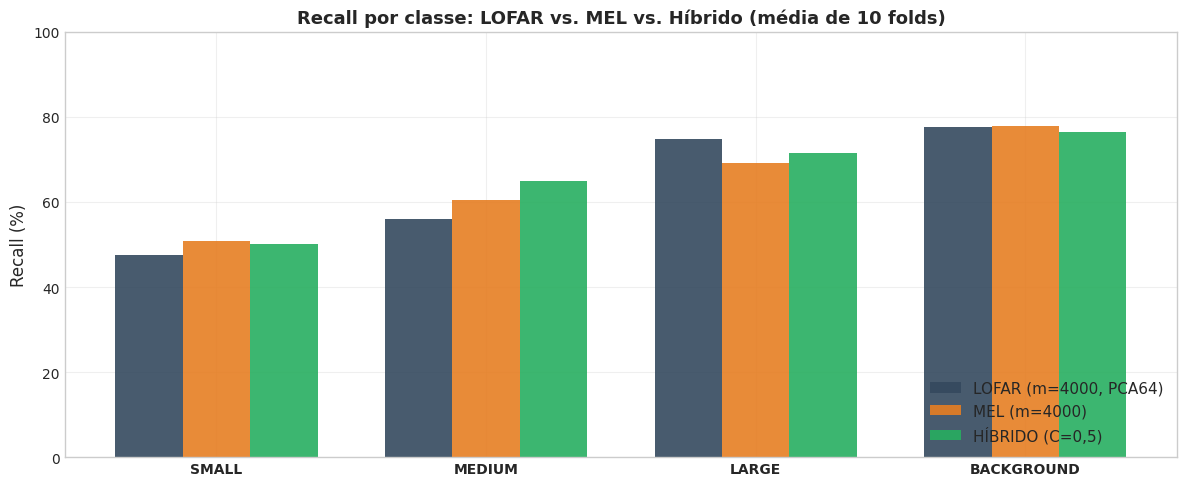

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Recalls por classe lidos dos experimentos (não digitados)
classes = ['SMALL', 'MEDIUM', 'LARGE', 'BACKGROUND']
series = [
    ('LOFAR (m=4000, PCA64)', R.summary('svm_nystroem_4000_lofar_pca64_elasticnet_l1r0.15_C2.0'), '#34495e'),
    ('MEL (m=4000)', R.summary('svm_nystroem_4000_log_melgram_elasticnet_l1r0.15_C2.0'), '#e67e22'),
    ('HÍBRIDO (C=0,5)', R.summary('svm_nystroem_4000_hybrid_norm_elasticnet_l1r0.15_C0.5'), '#27ae60'),
]

x = np.arange(len(classes))
width = 0.25
plt.figure(figsize=(12, 5))
for i, (rot, s, cor) in enumerate(series):
    plt.bar(x + (i - 1) * width, [s['R_' + c][0] for c in classes], width, label=rot, color=cor, alpha=0.9)
plt.title('Recall por classe: LOFAR vs. MEL vs. Híbrido (média de 10 folds)', fontweight='bold')
plt.xticks(x, classes, fontweight='bold')
plt.ylabel('Recall (%)')
plt.ylim(0, 100)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Conclusões e Síntese

*(Números calculados dos CSVs em disco na geração deste notebook; conferir com as saídas acima.)*

1. **LOFAR × MEL:**
   * O **LOFAR** tem o maior recall de `LARGE` entre os SVMs (74,91% com PCA64; 76,31% com m=6000), mas o recall de `SMALL` fica entre 38,15% (m=6000) e 47,64% (PCA64).
   * O **MEL** (m=4000) tem o menor desvio de SP entre os SVMs (σ = 1,14 p.p.) e recall de `SMALL` de 50,73%. O recall de `BACKGROUND` do MEL (77,86%) é **menor** que o do LOFAR m=6000 (87,04%).
   * Em SP, MEL (63,78 ± 1,14) e LOFAR m=6000 (63,83 ± 1,91) são **equivalentes** (F-test 5×2cv, p = 0,096).

2. **Fusão Híbrida:**
   * O Híbrido MEL + LOFAR-PCA64 (C = 0,5) atinge SP 65,16 ± 1,67 (ACC balanceada 65,77 ± 1,55), com recalls 50,2/64,8/71,5/76,5 (SMALL/MEDIUM/LARGE/BACKGROUND).
   * A diferença **não é estatisticamente significativa** contra o MEL (p = 0,304), o LOFAR m=6000 (p = 0,213) ou o MLP LOFAR local (p = 0,414). Além disso, o C = 0,5 foi escolhido pelo teste (com C = 2,0 o SP é 64,67). Portanto o Híbrido é **equivalente** às representações isoladas, e não uma "vitória".

3. **Cascata no nível de arquivo (LOFAR-MC → especialista SMALL × LARGE):**
   * Com o especialista **retreinado sem vazamento**, a cascata atinge SP **66,00 ± 1,90**, ACC 66,77 ± 1,92, recall `SMALL` 51,74% (estágio 1: 38,15%) e `LARGE` 67,99% (estágio 1: 76,31%): o ganho em `SMALL` é pago com parte do `LARGE`.
   * Contra o estágio 1 (SP 63,83 ± 1,91), o F-test dá p = 0,030 (diferença significativa a 5%). Contra o MLP LOFAR local (66,24 ± 1,78), p = 0,371: **equivalente**. Contra o MLP LOFAR do artigo (66,51 ± 1,39), fica **dentro do desvio** (o artigo não traz predições por fold, então não há F-test). A cascata **não supera** o melhor baseline.
   * O valor reportado antes, SP 68,56 ± 1,67, vinha do especialista com vazamento (49,1% dos arquivos de teste no treino dele) e superestimava a cascata em 2,56 p.p. **Não deve ser citado.**
   * **Cascatas por janela** (seção 5.2), também com o especialista retreinado: a melhor, `lofarmc6000_nosm`, dá SP 67,16 ± 1,82 (antes, com o especialista vazado: 69,46 ± 2,25), significativamente acima do seu estágio 1 (p = 0,007) e **equivalente** ao MLP LOFAR (p = 0,563). O valor de 69,48% citado para essa cascata em `presentation/apresentacao-resultados.tex` vinha do especialista vazado e não se sustenta.

4. **Relação com o DEMON:**
   * LOFAR e MEL cobrem o espectro direto de 0 a 8 kHz (após decimação para 16 kHz); o **DEMON** descreve a modulação de envoltória (0,39 a 25 Hz), ligada à rotação do hélice. Se essa informação ajuda a separar `SMALL` de `LARGE` é uma hipótese a ser testada nos notebooks de DEMON, não uma conclusão deste notebook.
